# Milestone 2 - RLE and exploratory analysis
Notebook for GitHub: `notebooks/milestone-2-questions.ipynb` (branch `milestone-2`).

Covers: RLE encoding on an 8x8 grid (Q1), RLE decoding of one training image (Q2), class prevalence (Q3), defect co-occurrence (Q4). The printed lines at the end of each section are in the official answer format.

## Setup

In [9]:
import os, glob, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IMG_H, IMG_W = 128, 800
DEFECTS = ["defect_a", "defect_b", "defect_c", "defect_d"]

KNOWN_TRAIN = "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv"

def find_train_csv():
    """Use the known Kaggle path; otherwise search /kaggle/input and the working folder."""
    if os.path.exists(KNOWN_TRAIN):
        return KNOWN_TRAIN
    for root in ["/kaggle/input", "."]:
        hits = glob.glob(os.path.join(root, "**", "train.csv"), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError("train.csv not found - attach the competition data to this notebook")

TRAIN_CSV = find_train_csv()
print("Using:", TRAIN_CSV)

Using: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv


## RLE utilities
Conventions: 1-based start index, column-major (Fortran) traversal. `rle_encode` closes runs with zero padding and detects value changes; `rle_decode` is its inverse and treats NaN/blank as an empty mask.

In [10]:
def rle_encode(mask):
    """Binary 2D mask -> RLE string. 1-based start index, column-major (Fortran) order."""
    flat = np.asarray(mask).flatten(order="F")         
    padded = np.concatenate([[0], flat, [0]])         
    k = np.where(padded[1:] != padded[:-1])[0] + 1    
    starts, ends = k[0::2], k[1::2]                   
    return " ".join(f"{s} {e - s}" for s, e in zip(starts, ends))

def rle_decode(rle, shape=(IMG_H, IMG_W)):
    """RLE string -> binary (H, W) mask. NaN / empty / blank string -> all zeros."""
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tok = np.array(rle.split(), dtype=np.int64)
        starts = tok[0::2] - 1                        
        ends = starts + tok[1::2]
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1     
    return flat.reshape(shape, order="F")             

In [11]:
rng = np.random.default_rng(0)
for _ in range(200):
    m = (rng.random((IMG_H, IMG_W)) > 0.9).astype(np.uint8)
    assert (rle_decode(rle_encode(m)) == m).all()
print("round-trip test passed")

round-trip test passed


## Q1 - RLE of the 8 x 8 grid
Cells are numbered 1..64 down the columns. The highlighted cells were read from the figure of the question. The mask is encoded with `rle_encode` and cross-checked with an independent rule (group consecutive cell numbers into runs).

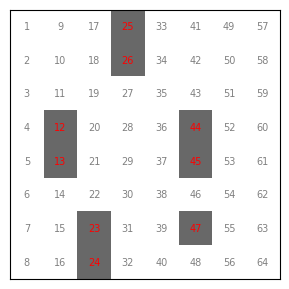

Q1 rle_string: 12 2 23 4 44 2 47 1


In [12]:
HIGHLIGHTED = [12, 13, 23, 24, 25, 26, 44, 45, 47]

def cells_to_mask(cells, n=8):
    flat = np.zeros(n * n, dtype=np.uint8)
    flat[np.array(cells) - 1] = 1
    return flat.reshape((n, n), order="F")

def runs_from_cells(cells):
    cells = sorted(cells)
    runs, start, prev = [], cells[0], cells[0]
    for c in cells[1:]:
        if c != prev + 1:
            runs.append((start, prev - start + 1))
            start = c
        prev = c
    runs.append((start, prev - start + 1))
    return " ".join(f"{s} {l}" for s, l in runs)

grid = cells_to_mask(HIGHLIGHTED)
fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(grid, cmap="Greys", vmin=0, vmax=1.5)
for n in range(1, 65):
    r, c = (n - 1) % 8, (n - 1) // 8
    ax.text(c, r, str(n), ha="center", va="center", color="red" if grid[r, c] else "gray", fontsize=7)
ax.set_xticks([]); ax.set_yticks([])
plt.show()

assert rle_encode(grid) == runs_from_cells(HIGHLIGHTED)
print("Q1 rle_string:", rle_encode(grid))

## Q2 - decode the four masks of image `0ZUU8LH57Y`
Each defect row is decoded to a `(128, 800)` binary mask; empty entries (NaN) become all-zero masks. The answer is the sum of all positive pixels over the four masks.

In [13]:
train = pd.read_csv(TRAIN_CSV)
print("rows:", len(train), "| images:", train["image_id"].nunique())

IMAGE_ID = "0ZUU8LH57Y"
rows = train[train["image_id"] == IMAGE_ID].set_index("defect_type").reindex(DEFECTS)
masks = {d: rle_decode(rows.loc[d, "mask_rle"]) for d in DEFECTS}
per_class = {d: int(m.sum()) for d, m in masks.items()}
assert all(m.shape == (IMG_H, IMG_W) for m in masks.values())
print("pixels per class:", per_class)
print("Q2 total positive pixels:", sum(per_class.values()))

rows: 45572 | images: 11393
pixels per class: {'defect_a': 250, 'defect_b': 0, 'defect_c': 1232, 'defect_d': 5032}
Q2 total positive pixels: 6514


## Q3 - class prevalence
A class is present in an image when its `mask_rle` is neither NaN nor blank. The file has exactly four rows per image, so counting present rows per class equals counting images per class.

In [14]:
train["present"] = train["mask_rle"].fillna("").str.strip().ne("")
assert len(train) == 4 * train["image_id"].nunique()

counts = train.groupby("defect_type")["present"].sum().astype(int).sort_values(ascending=False)
print(counts.to_string())
print(f"Q3 most_common ({counts.index[0]}, {counts.iloc[0]}), rarest ({counts.index[-1]}, {counts.iloc[-1]})")

defect_type
defect_c    4100
defect_d    1707
defect_a    1081
defect_b     313
Q3 most_common (defect_c, 4100), rarest (defect_b, 313)


## Q4 - co-occurrence matrix
`P` is the binary image x class presence matrix; `C = P.T @ P` counts images containing both classes, with image counts on the diagonal.

In [15]:
P = (train.pivot_table(index="image_id", columns="defect_type", values="present", aggfunc="max")
          .astype(int)[DEFECTS])
C = pd.DataFrame(P.values.T @ P.values, index=DEFECTS, columns=DEFECTS)
print(C.to_string())

assert (np.diag(C.values) == counts.reindex(DEFECTS).values).all()
pairs = {(i, j): int(C.loc[i, j]) for i, j in itertools.combinations(DEFECTS, 2)}
best = max(pairs, key=pairs.get)
assert ((P[best[0]] == 1) & (P[best[1]] == 1)).sum() == pairs[best]   # brute-force check
print(f"Q4 defect_pair, count: {best[0]} & {best[1]}, {pairs[best]}")

          defect_a  defect_b  defect_c  defect_d
defect_a      1081        42       310       234
defect_b        42       313        95        64
defect_c       310        95      4100       705
defect_d       234        64       705      1707
Q4 defect_pair, count: defect_c & defect_d, 705


## Q5 - co-occurrence versus correlation
A high joint count can simply mean both classes are frequent. Correlation removes that base-rate effect.

Two readings of the question wording are possible, so both are computed:
- **(a) correlation of the presence columns**: Pearson correlation between the 0/1 columns of `P`. For two binary variables this is the phi coefficient. It compares the observed joint count with what independence would give.
- **(b) `np.corrcoef` applied to the rows of the 4 x 4 matrix `C`**: it correlates the *profiles* of the classes, which are dominated by the large diagonal (the marginal frequencies), so it mixes the base-rate effect back in.

Reading (a) is the statistically meaningful one and is used for the answer.

In [16]:
top_a, top_b = best                                  
a, b = P[top_a].to_numpy(), P[top_b].to_numpy()
N = len(P)

n11 = int(((a == 1) & (b == 1)).sum()); n10 = int(((a == 1) & (b == 0)).sum())
n01 = int(((a == 0) & (b == 1)).sum()); n00 = int(((a == 0) & (b == 0)).sum())
phi_manual = (n11 * n00 - n10 * n01) / np.sqrt((n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00))

corr_presence = pd.DataFrame(np.corrcoef(P.to_numpy().T), index=DEFECTS, columns=DEFECTS)   # reading (a)
corr_cooc_rows = pd.DataFrame(np.corrcoef(C.to_numpy()), index=DEFECTS, columns=DEFECTS)    # reading (b)

print("reading (a) presence-column correlation:"); print(corr_presence.round(2).to_string())
print("\nreading (b) corrcoef of the C rows:");   print(corr_cooc_rows.round(2).to_string())

r_a, r_b = corr_presence.loc[top_a, top_b], corr_cooc_rows.loc[top_a, top_b]
assert abs(r_a - phi_manual) < 1e-9                 
expected = N * a.mean() * b.mean()                  
print(f"\npair {top_a} & {top_b}: observed joint {n11}, expected by chance {expected:.1f}, lift {n11 / expected:.2f}")
print(f"(a) phi = {r_a:.4f}   (b) row-profile corr = {r_b:.4f}")

reading (a) presence-column correlation:
          defect_a  defect_b  defect_c  defect_d
defect_a      1.00      0.02     -0.05      0.06
defect_b      0.02      1.00     -0.02      0.03
defect_c     -0.05     -0.02      1.00      0.05
defect_d      0.06      0.03      0.05      1.00

reading (b) corrcoef of the C rows:
          defect_a  defect_b  defect_c  defect_d
defect_a      1.00     -0.65     -0.15     -0.25
defect_b     -0.65      1.00     -0.27     -0.51
defect_c     -0.15     -0.27      1.00      0.15
defect_d     -0.25     -0.51      0.15      1.00

pair defect_c & defect_d: observed joint 705, expected by chance 614.3, lift 1.15
(a) phi = 0.0465   (b) row-profile corr = 0.1543


In [17]:
r_answer = r_a
verdict = "Yes" if abs(r_answer) >= 0.5 else "No"
print(f"Q5 correlation_value, Yes/No: {r_answer:.2f}, {verdict}")

Q5 correlation_value, Yes/No: 0.05, No


## Q6 - pixel-level overlap between classes
For every image with two or more defects, decode the masks of the present classes on the native 128 x 800 canvas and compute for every distinct pair the intersection `|Mi and Mj|` and the Dice `2|Mi and Mj| / (|Mi| + |Mj|)`.

In [18]:
wide = train.pivot(index="image_id", columns="defect_type", values="mask_rle").reindex(columns=DEFECTS)
multi_ids = P.index[P.sum(axis=1) >= 2]
print("multi-label images:", len(multi_ids))

max_overlap, max_dice, n_pairs, n_overlapping, worst = 0, 0.0, 0, 0, None
for img in multi_ids:
    present = [d for d in DEFECTS if P.at[img, d] == 1]
    dec = {d: rle_decode(wide.at[img, d]).astype(bool) for d in present}
    for u, v in itertools.combinations(present, 2):
        inter = int((dec[u] & dec[v]).sum())
        dice = 2 * inter / (dec[u].sum() + dec[v].sum())
        n_pairs += 1
        n_overlapping += inter > 0
        if inter > max_overlap:
            max_overlap, worst = inter, (img, u, v)
        max_dice = max(max_dice, dice)

print("pairs checked:", n_pairs, "| pairs with any shared pixel:", n_overlapping)
print("max overlap (pixels):", max_overlap, "| max Dice:", round(max_dice, 4), "| worst:", worst)
print(f"Q6 max_overlap_pixels, Yes/No: {max_overlap}, {'Yes' if max_overlap == 0 else 'No'}")

multi-label images: 1198
pairs checked: 1450 | pairs with any shared pixel: 0
max overlap (pixels): 0 | max Dice: 0.0 | worst: None
Q6 max_overlap_pixels, Yes/No: 0, Yes


## Q7 - PyTorch Dataset for Paradigm 1
`__getitem__` loads one image (BGR to RGB, divide by 255) and decodes its four RLE masks into a `(4, 128, 800)` float32 tensor. `__len__` is the number of unique images.

In [19]:
import cv2
import torch
from torch.utils.data import Dataset, DataLoader

def find_image_dir(sample_id):
    """Locate the folder that holds the training images (by looking for one known image)."""
    hits = glob.glob(f"/kaggle/input/**/{sample_id}.*", recursive=True) or glob.glob(f"./**/{sample_id}.*", recursive=True)
    if not hits:
        raise FileNotFoundError(f"image {sample_id} not found - attach the competition data")
    return os.path.dirname(hits[0])

class SurfaceAnomalyDataset(Dataset):
    """Paradigm 1: one sample = one image -> (3,128,800) float32 in [0,1], (4,128,800) float32 masks."""
    def __init__(self, df, img_dir):
        self.img_dir = img_dir
        # long format (image, class, rle) -> one row per image, one column per class, fixed order a..d
        wide = df.pivot(index="image_id", columns="defect_type", values="mask_rle").reindex(columns=DEFECTS)
        self.ids = wide.index.to_list()
        self.rles = wide.to_numpy(dtype=object)               # (n_images, 4), NaN where empty
        self.files = {os.path.splitext(f)[0]: f for f in os.listdir(img_dir)}   # image_id -> file name

    def __len__(self):
        return len(self.ids)                                  # number of UNIQUE images, not rows

    def __getitem__(self, idx):
        path = os.path.join(self.img_dir, self.files[self.ids[idx]])
        bgr = cv2.imread(path, cv2.IMREAD_COLOR)              # OpenCV returns channels in B,G,R order
        if bgr is None:
            raise FileNotFoundError(path)
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)            # reorder to R,G,B
        image = torch.from_numpy(rgb.astype(np.float32) / 255.0).permute(2, 0, 1).contiguous()  # (H,W,3)->(3,H,W)
        masks = np.stack([rle_decode(r) for r in self.rles[idx]]).astype(np.float32)            # (4,H,W)
        return image, torch.from_numpy(masks)

In [20]:
IMG_DIR = find_image_dir(IMAGE_ID)
print("image folder:", IMG_DIR)

ds = SurfaceAnomalyDataset(train, IMG_DIR)
print("len(ds) =", len(ds), "(unique images:", train["image_id"].nunique(), ")")

loader = DataLoader(ds, batch_size=4, shuffle=False)
images, masks = next(iter(loader))
print("images:", tuple(images.shape), images.dtype, "| range", float(images.min()), "to", float(images.max()))
print("masks :", tuple(masks.shape), masks.dtype, "| unique values", masks.unique().tolist())
print(f"Q7 images_shape, masks_shape, dtype: {tuple(images.shape)}, {tuple(masks.shape)}, {images.dtype}")

image folder: /kaggle/input/competitions/industrial-surface-defect-detection/public/train
len(ds) = 11393 (unique images: 11393 )
images: (4, 3, 128, 800) torch.float32 | range 0.0 to 1.0
masks : (4, 4, 128, 800) torch.float32 | unique values [0.0, 1.0]
Q7 images_shape, masks_shape, dtype: (4, 3, 128, 800), (4, 4, 128, 800), torch.float32


In [21]:
import torch.nn as nn
loss_fn = nn.BCEWithLogitsLoss()
logits = torch.randn(2, 4, 8, 8)
target_float = (torch.rand(2, 4, 8, 8) > 0.5).float()
print("float32 target ->", loss_fn(logits, target_float).item())
for bad in [target_float.to(torch.uint8), target_float.bool()]:
    try:
        loss_fn(logits, bad)
    except Exception as e:
        print(f"{bad.dtype} target -> {type(e).__name__}: {str(e)[:90]}")

float32 target -> 0.8472112417221069
torch.uint8 target -> RuntimeError: result type Float can't be cast to the desired output type Byte
torch.bool target -> RuntimeError: Subtraction, the `-` operator, with two bool tensors is not supported. Use the `^` or `log
